In [1]:
%pip install -q otter-grader

Note: you may need to restart the kernel to use updated packages.


# Case Study 10: Predicting Diabetes Progression for a Care-Management Program

**DS701 — Session 12 (Wed Oct 14, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/10-InClass-Exercise-Linear-Regression-A1/10-InClass-Exercise-Linear-Regression-A1.ipynb)

**Time: ~45 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked.

**Plan**

| Part | The care-management program's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | From BMI alone, how much more progression per BMI unit — and what should we expect for a patient at BMI 30? | Design matrix, normal equations, $R^2$ by hand | autograded | ~10 min |
| 2 | Why is *that* the line, and not another? (they will not ask — you must own it) | Least squares as projection: the hat matrix, residuals $\perp$ columns, leverage | autograded | ~8 min |
| 3 | We also record serum triglycerides. Does adding them change what the BMI number means? | A second, correlated feature enters — watch the coefficients move | autograded | ~10 min |
| 4 | Does the model fit all patients equally, or is it worse for the sickest? | Residual diagnostics: a `diagnostics` function and the plots to read | autograded | ~8 min |
| — | Report out: what you would tell the care-management program | team memo, then pair-share | participation | ~10 min |

Dependencies: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`.


## Case Study Setup

You are a data scientist for a primary-care network's **diabetes care-management
program**. The program's nurses have a fixed number of outreach calls a month and want
to spend them on the patients whose disease is most likely to progress. They have asked
you which of the measurements taken at a patient's baseline visit predict **progression
a year later**, by how much, and whether the model's numbers can be trusted — because a
nurse will act on them: a patient flagged "high" gets a call, a patient flagged "low"
does not.

Before the network's own records are released to you (that takes a data-use agreement
and IRB review), they have asked you to build a prototype on the public **diabetes**
dataset of Efron, Hastie, Johnstone and Tibshirani (2004), which ships with
`scikit-learn`, so nothing is downloaded:

- **442 patients** with ten baseline measurements — age, sex, body-mass index (`bmi`),
  blood pressure (`bp`) and six blood-serum values (`s1`–`s6`; `s5` is the log of serum
  triglycerides) — and the target, a **quantitative measure of disease progression one
  year later**.
- We load it in its *raw units* (`scaled=False`), so a slope means something a nurse can
  repeat: "one BMI unit is worth this many progression points".
- The activity works on a **random subset of 200 patients**, chosen by the section seed.

**What the care-management program asked you, and where you answer it**

1. *From BMI alone, how much more progression should we expect per BMI unit — and what
   does that predict for a patient with BMI 30?* — Part 1
2. *Why is that the line and not another one?* They will not ask this; you must be able
   to answer it anyway. — Part 2
3. *Our nurses also record serum triglycerides at the baseline visit. If we add that,
   does what the BMI number "means" change?* — Part 3
4. *Does the model fit all patients equally, or is it worse for the sickest?* — Part 4

A prototype for discussion, not a clinical tool: nothing here is validated for
patient care, and none of it is a causal claim.

Notation, exactly as in the lecture: $n$ observations, design matrix $X$ ($n \times p$,
**first column all ones** for the intercept), observations $\mathbf{y}$, parameters
$\beta$, fitted values $\hat{\mathbf{y}} = X\hat\beta$, residuals
$\mathbf{e} = \mathbf{y} - \hat{\mathbf{y}}$.

Run the next four cells as-is — everything below depends on them.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

In [3]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED)

In [4]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/10-InClass-Exercise-Linear-Regression-A1/tests/"
    for _q in ("q1", "q2", "q3", "q4"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")

In [5]:
# Initialize Otter
import otter
grader = otter.Notebook()

In [6]:
diabetes = load_diabetes(scaled=False, as_frame=True)
df_all = diabetes.frame          # 442 rows: age, sex, bmi, bp, s1..s6, target

# This section's subset: 200 of the 442 patients, chosen by the section seed.
idx = np.sort(rng.choice(len(df_all), 200, replace=False))
df = df_all.iloc[idx].reset_index(drop=True)

y = df["target"].to_numpy(dtype=float)     # disease progression (what we predict)
bmi = df["bmi"].to_numpy(dtype=float)      # body-mass index
s5 = df["s5"].to_numpy(dtype=float)        # log of serum triglycerides (used in Part 3)
n = len(y)

print(f"Section {SECTION}: {n} patients")
df[["age", "bmi", "bp", "s5", "target"]].describe().loc[["mean", "std", "min", "max"]].round(2)

Section A1: 200 patients


,age,bmi,bp,s5,target
mean,48.85,26.42,95.88,4.64,151.72
std,13.24,4.65,13.84,0.52,79.28
min,19.00,18.00,65.00,3.53,31.00
max,79.00,38.30,126.00,6.11,341.00


One feature first. Progression against BMI looks roughly linear with a lot of scatter —
exactly the situation the lecture opened with: *no line goes through all the points, so
which line is best?*

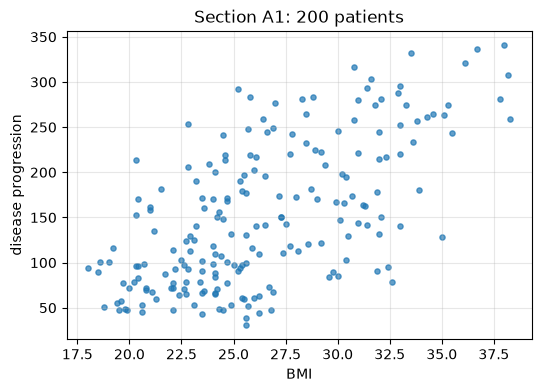

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(bmi, y, s=14, alpha=0.7)
plt.xlabel("BMI"); plt.ylabel("disease progression"); plt.title(f"Section {SECTION}: {n} patients")
plt.grid(alpha=0.3)
plt.show()

## Part 1 (autograded): least squares by hand

**Why.** The program's first question is the simplest one: *from BMI alone, how much
more progression should we expect per BMI unit, and what does that predict for a
patient with BMI 30?* A straight line through the scatter above is that answer, and
least squares is how the line is chosen. Before you trust `scikit-learn` to choose it,
you solve the normal equations yourself — so that when a nurse asks where the number
came from, you can say.

The model is $y = \beta_0 + \beta_1\,\text{bmi} + \epsilon$. Stacking the $n$ equations
gives $X\beta = \mathbf{y}$ with

$$
X = \begin{bmatrix} 1 & \text{bmi}_1 \\ \vdots & \vdots \\ 1 & \text{bmi}_n \end{bmatrix},
$$

which has no exact solution. The least-squares $\hat\beta$ minimises
$\lVert X\beta - \mathbf{y}\rVert^2$ and solves the **normal equations**
$X^\top X\,\beta = X^\top\mathbf{y}$.

**Task.**

1. Build the design matrix `X1` (shape `(n, 2)`, **column of ones first**, then `bmi`).
2. Solve the normal equations for `beta_ne` — a length-2 array `[intercept, slope]`.
   Use `np.linalg.solve(X1.T @ X1, X1.T @ y)` (numerically nicer than forming the
   inverse, though `np.linalg.inv(X1.T @ X1) @ X1.T @ y` gives the same answer here).
3. Verify against two library routines: `beta_lstsq = np.linalg.lstsq(X1, y, rcond=None)[0]`
   and `beta_sk`, the `[intercept_, coef_[0]]` of `LinearRegression().fit(bmi.reshape(-1, 1), y)`.
4. Compute `r2_1` **by hand** from the definitions: `RSS = sum((y - y_hat)**2)`,
   `TSS = sum((y - y.mean())**2)`, $R^2 = 1 - \text{RSS}/\text{TSS}$. (Check it against
   `LinearRegression(...).score(...)` if you like.)
5. `pred_bmi30`: the model's predicted progression for a patient with BMI 30, as a `float`.

normal equations : [-134.4275   10.8307]
np.linalg.lstsq  : [-134.4275   10.8307]
sklearn          : 10.8307
R^2 (by hand) = 0.4027   sklearn .score() = 0.4027
predicted progression at BMI 30: 190.5


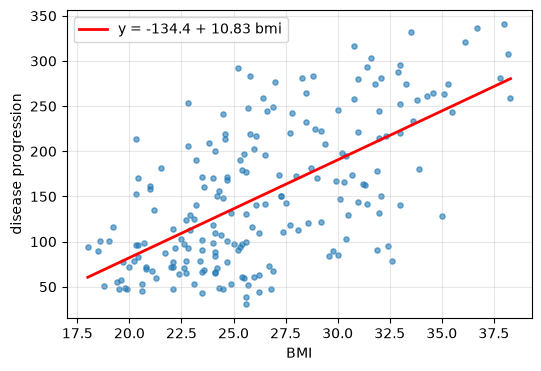

In [ ]:
X1 = np.column_stack((np.ones(n), bmi))  # add a column of 1s for the intercept

beta_ne = np.linalg.inv(X1.T @ X1) @ X1.T @ y
beta_lstsq = np.linalg.lstsq(X1, y, rcond=None)[0]
_sk1 = LinearRegression().fit(bmi.reshape(-1, 1), y)
beta_sk = _sk1.coef_[0]

R2_1 = 1 - np.sum((y - (beta_ne[0] + beta_ne[1] * bmi))**2) / np.sum((y - y.mean())**2)
r2_1 = R2_1
pred_bmi30 = beta_ne[0] + beta_ne[1] * 30

print("normal equations :", np.round(beta_ne, 4))
print("np.linalg.lstsq  :", np.round(beta_lstsq, 4))
print("sklearn          :", np.round(beta_sk, 4))
print(f"R^2 (by hand) = {r2_1:.4f}   sklearn .score() = {_sk1.score(bmi.reshape(-1, 1), y):.4f}")
print(f"predicted progression at BMI 30: {pred_bmi30:.1f}") # Calculating the predicted disease progression for a BMI of 30.

plt.figure(figsize=(6, 4))
plt.scatter(bmi, y, s=14, alpha=0.6)
_grid = np.linspace(bmi.min(), bmi.max(), 50)
plt.plot(_grid, beta_ne[0] + beta_ne[1] * _grid, "r-", lw=2, label=f"y = {beta_ne[0]:.1f} + {beta_ne[1]:.2f} bmi")
plt.xlabel("BMI"); plt.ylabel("disease progression"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Discuss (participation):** write the one sentence about BMI that would go in your memo
to the program, with units. Then: the intercept is a large *negative* number, and a
nurse reading the coefficient table asks whether the model is broken. What does
$\beta_0$ actually mean here, and is BMI $=0$ anywhere near any patient they will ever
call?

*Each 1 kg/m² higher BMI is associated with an average increase of about 10.8 points in one-year disease progression, with BMI alone explaining roughly 40% of the variation.*

*β₀ = -134.4 is the predicted progression at BMI = 0, which no patient has (the data span about BMI 18 to 38), so it's an extrapolation off the left edge of the plot with no clinical meaning, not a sign the model is broken.*


In [12]:
grader.check("q1")

q1 results:
    q1 - 1 result:
        ✅ Test case passed

    q1 - 2 result:
        ❌ Test case failed
        Error at line 19 in test q1:
                  assert np.asarray(b).shape == (2,), 'each beta must be a length-2 array [intercept, slope]'
        AssertionError: each beta must be a length-2 array [intercept, slope]

## Part 2 (autograded): least squares *is* a projection

**Why.** The program will never ask *why that line and not another* — but you must own
the answer, because every number you hand them in Parts 1, 3 and 4 rests on it. The
answer: $\hat{\mathbf{y}} = X\hat\beta$ is the vector in the **column space of $X$**
closest to $\mathbf{y}$ — its orthogonal projection — and the residual
$\mathbf{e} = \mathbf{y} - \hat{\mathbf{y}}$ is therefore **perpendicular to every
column of $X$**: $X^\top\mathbf{e} = \mathbf{0}$, which is the normal equations
rearranged.

Substituting $\hat\beta = (X^\top X)^{-1}X^\top\mathbf{y}$ gives
$\hat{\mathbf{y}} = P\,\mathbf{y}$ with the **projection ("hat") matrix**

$$
P = X\,(X^\top X)^{-1}X^\top \qquad (n \times n).
$$

**Task.** Using `X1` and `y` from Part 1:

1. Form `P` and `y_hat_P = P @ y`; confirm it equals `X1 @ beta_ne`.
2. `resid = y - y_hat_P`.
3. `max_abs_xt_e = float(np.abs(X1.T @ resid).max())` — the largest dot product between a
   column of $X$ and the residual. It should be zero up to floating point.
4. `P_trace = float(np.trace(P))`, `sym_err = float(np.abs(P - P.T).max())`,
   `idem_err = float(np.abs(P @ P - P).max())` — a projection matrix is symmetric,
   idempotent ($P^2 = P$), and its trace is the dimension of the space projected onto.
5. `leverage = np.diag(P)` — entry $i$ says how much observation $i$ pulls its *own*
   fitted value ($\partial\hat y_i / \partial y_i$). Set `mean_leverage = float(leverage.mean())`.
   Keep this idea: it comes back in Part 4.

In [14]:
P = X1 @ np.linalg.inv(X1.T @ X1) @ X1.T # projection matrix
y_hat_P = P @ y # predicted values from the projection matrix
resid = y - y_hat_P # residuals
max_abs_xt_e = np.max(np.abs(X1.T @ resid)) # maximum absolute value of the inner product of the design matrix and the residuals
P_trace = np.trace(P) # trace of the projection matrix, which should equal the number of parameters (p) in the model
sym_err = np.linalg.norm(P - P.T, ord="fro") # Frobenius norm of the difference between the projection matrix and its transpose, which should be close to zero for a symmetric matrix
idem_err = np.linalg.norm(P @ P - P, ord="fro") # Frobenius norm of the difference between the projection matrix and its square, which should be close to zero for an idempotent matrix
leverage = np.diag(P) # leverage values for each observation, which measure the influence of each observation on the fitted values
mean_leverage = leverage.mean() # mean leverage, which should equal p/n, where p is the number of parameters and n is the number of observations


print("P shape:", P.shape)
print("P @ y == X1 @ beta_ne ?", np.allclose(y_hat_P, X1 @ beta_ne))
print(f"max |X^T e|          = {max_abs_xt_e:.2e}   (residual orthogonal to both columns)")
print(f"sum of residuals     = {resid.sum():.2e}   (the intercept column is all ones)")
print(f"trace(P) = {P_trace:.6f}   symmetric err = {sym_err:.1e}   idempotent err = {idem_err:.1e}")
print(f"leverage: mean = {mean_leverage:.4f} (= p/n = {X1.shape[1]}/{n}), max = {leverage.max():.4f} at patient {int(leverage.argmax())} (BMI {bmi[leverage.argmax()]:.1f})")

P shape: (200, 200)
P @ y == X1 @ beta_ne ? True
max |X^T e|          = 8.83e-10   (residual orthogonal to both columns)
sum of residuals     = 4.43e-11   (the intercept column is all ones)
trace(P) = 2.000000   symmetric err = 1.3e-15   idempotent err = 5.2e-15
leverage: mean = 0.0100 (= p/n = 2/200), max = 0.0379 at patient 65 (BMI 38.3)


**Discuss (participation):** an analyst on the program's team suggests dropping the
intercept "to keep the model simpler". Your `resid.sum()` is zero to machine precision:
which column of $X$ is responsible for that, and what would happen to it — and to the
$R^2 = 1 - \text{RSS}/\text{TSS}$ you report to the program — if you fit the model
*without* an intercept?

*The column of ones is responsible: the normal equations force Xᵀe = 0, and its first row says Σeᵢ = 0. Without an intercept, that guarantee disappears and the line is forced through the origin. Since the true intercept here is about -134, the fit would be badly biased, and R² = 1 − RSS/TSS stops being meaningful (RSS can even exceed TSS, giving a negative R²).*


In [15]:
grader.check("q2")

q2 results: All test cases passed!

## Part 3 (autograded): a second, correlated feature enters

**Why.** The nurses also record serum triglycerides at the baseline visit, and the
program wants to know whether adding them changes what the BMI number "means". Add
`s5` (log of serum triglycerides) as a second predictor:
$y = \beta_0 + \beta_1\,\text{bmi} + \beta_2\,\text{s5} + \epsilon$. In this subset
`bmi` and `s5` are moderately correlated (check `np.corrcoef(bmi, s5)`), so the two
columns of $X$ partly point in the same direction — and the projection has to *share*
the explained part between them. Watch what that does to the BMI coefficient.

**Task.**

1. `X2` — the `(n, 3)` design matrix `[1, bmi, s5]`.
2. `beta_2` — the least-squares solution (normal equations again).
3. `r2_2` — $R^2$ by hand, as in Part 1.
4. `pred2_bmi30_s5` — predicted progression for BMI 30 and s5 equal to **the subset mean of `s5`**, as a `float`.
5. `bmi_coef_change = float(beta_2[1] - beta_ne[1])` — how much the BMI coefficient moved
   when `s5` entered.

In [18]:
print(f"corr(bmi, s5) in this subset = {np.corrcoef(bmi, s5)[0, 1]:.3f}")

bmi_coef_change = 0.0
X2 = np.column_stack((np.ones(n), bmi, s5))
beta_2 = np.linalg.inv(X2.T @ X2) @ X2.T @ y
R2_2 = 1 - np.sum((y - (beta_2[0] + beta_2[1] * bmi + beta_2[2] * s5))**2) / np.sum((y - y.mean())**2)
r2_2 = R2_2
pred2_bmi30_s5 = beta_2[0] + beta_2[1] * 30 + beta_2[2] * s5.mean()

print("one feature  [b0, b_bmi]      :", np.round(beta_ne, 3), f"  R^2 = {r2_1:.4f}")
print("two features [b0, b_bmi, b_s5]:", np.round(beta_2, 3), f"  R^2 = {r2_2:.4f}")
print(f"BMI coefficient moved by {bmi_coef_change:+.3f}")
print(f"prediction at BMI 30, s5 = mean: {pred2_bmi30_s5:.1f}   (one-feature model said {pred_bmi30:.1f})")

corr(bmi, s5) in this subset = 0.441
one feature  [b0, b_bmi]      : [-134.428   10.831]   R^2 = 0.4027
two features [b0, b_bmi, b_s5]: [-339.774    7.817   61.439]   R^2 = 0.5315
BMI coefficient moved by +0.000
prediction at BMI 30, s5 = mean: 179.7   (one-feature model said 190.5)


**Discuss (participation):** the BMI coefficient dropped by about 3 points per BMI unit
when `s5` entered, yet nothing about the patients changed. The program's director asks:
*"So was the BMI number you gave us in Part 1 wrong?"* Which of these is the right
reply — (a) yes, the Part-1 slope was *wrong*, (b) the two slopes answer *different
questions*, (c) `s5` is a better feature? Explain using the phrase "holding s5 fixed".
Also: $R^2$ went up — would it have gone up if you had added a column of random noise?
What does that mean for how the program should read an $R^2$ you report?

*(The Part-1 slope (10.8) answers: "Comparing patients who differ in BMI, how much does progression differ on average?" That comparison also picks up the effect of s5, because high-BMI patients tend to have higher s5 (corr = 0.44). The new slope (7.8) answers: "Comparing patients with the same s5 but different BMI, how much does progression differ?" Neither is wrong. Part 1 was a correct answer to the first question, not a mistake.*

*"Holding s5 fixed": the 7.8 is the BMI effect among patients with the same s5. About 3 of the 10.8 points per BMI unit were really s5 riding along with BMI, and the model now credits them to s5 instead. The patients didn't change, only the question did.*

*R² going up (0.403 → 0.532): yes, it would have gone up even with a column of random noise. Adding any column can never lower in-sample R², because the model can always set that coefficient to 0, and in practice noise gives a small positive bump by chance.*


In [19]:
grader.check("q3")

q3 results: All test cases passed!

## Part 4 (autograded): does the model fit all patients equally?

**Why.** A nurse acting on the model's number needs to know whether it is equally
reliable for every patient, or systematically worse for the sickest — the ones a
care-management program most needs to get right. $R^2$ cannot tell you: it says *how
much* variance the line explains, nothing about *whether a line was the right model* or
where it fails. The lecture's Ames plot of predicted-vs-true showed the model
under-predicting at both ends of the price range — you could see that only because you
**looked at the residuals**. Three questions a residual plot answers, and the pattern
that betrays each:

| assumption of the linear model | how it fails | what you see in residuals vs fitted | quick statistic |
|---|---|---|---|
| the mean of $y$ is linear in the columns of $X$ | **nonlinearity** — a term is missing | a curve / bow, not a flat band | correlation between residuals and (fitted $-$ mean)$^2$ |
| residual variance is constant | **heteroscedasticity** — spread grows with the fit | a fan or funnel | ratio of residual variance in the top half of fitted to the bottom half (a Breusch–Pagan-style check) |
| every observation counts about equally | **an influential point** — one $x$ far from the rest drags the line | one point far out in $x$, often *not* the largest residual | maximum leverage $h_{ii} = P_{ii}$ compared with the average $p/n$ (rule of thumb: above $3p/n$ deserves a look; a *lone* point several times higher than the rest is the alarm) |

Plus the **QQ plot** of residuals against normal quantiles: straight line = roughly
Gaussian residuals (which the $t$-tests and confidence intervals in a statsmodels summary
assume); heavy tails or a bent line say otherwise.

The plotting helper below is given. You will write the statistics.

In [ ]:
def diagnostic_plots(X, y, title=""):
    """Residuals vs fitted, normal QQ plot of residuals, and leverage per observation."""
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    fitted = X @ beta
    resid = y - fitted
    lev = np.diag(X @ np.linalg.inv(X.T @ X) @ X.T)
    n_, p_ = X.shape

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(fitted, resid, s=16, alpha=0.7)
    axes[0].axhline(0, color="red", lw=1)
    axes[0].set_xlabel("fitted values"); axes[0].set_ylabel("residuals"); axes[0].set_title("residuals vs fitted")
    stats.probplot(resid, dist="norm", plot=axes[1])
    axes[1].set_title("normal QQ plot of residuals")
    axes[2].stem(np.arange(n_), lev, basefmt=" ")
    axes[2].axhline(3 * p_ / n_, color="red", ls="--", lw=1, label="3 p / n")
    axes[2].set_xlabel("observation index"); axes[2].set_ylabel("leverage $h_{ii}$"); axes[2].set_title("leverage"); axes[2].legend()
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 4 (autograded): a `diagnostics` function, tried on the program's model

**Task.** Write `diagnostics(X, y)` that fits least squares (use `np.linalg.lstsq`) and
returns a `dict` with exactly these keys:

- `"r2"` — $R^2$ (centred, as in Part 1);
- `"curve"` — the Pearson correlation between the residuals and `(fitted - fitted.mean())**2`
  (use `np.corrcoef(...)[0, 1]`); near 0 for a straight-line relationship, large in
  magnitude when the residuals bow;
- `"var_ratio"` — sort observations by fitted value (`np.argsort(fitted)`); the *lower half*
  is the first `n // 2` of them, the *upper half* the rest; return
  `np.var(resid_upper) / np.var(resid_lower)` (default `np.var`, i.e. `ddof=0`); near 1
  when the spread is constant;
- `"max_leverage"` — the largest diagonal entry of the projection matrix, and
  `"i_max_leverage"` — its index as an `int`;
- `"leverage_ratio"` — `max_leverage / (p / n)`, how many times the average leverage the
  most extreme point carries.

Then run it on the two-feature diabetes model, `diag_good = diagnostics(X2, y)`, and call
`diagnostic_plots(X2, y, "diabetes: bmi + s5")` to *look*. This is what a model with no
obvious pathology looks like: a flat band, no fan, no lone bar. If the residuals fanned
out at high fitted values, the model would be least reliable for exactly the patients
the program most wants to reach — that is the caveat to carry into your memo. (With 200
patients the heaviest one will sit a bit above the $3p/n$ line; that is a tail, not a
problem. Watch for a *single* bar far above everything else.)

In [ ]:
def diagnostics(X, y):
    """Fit least squares and return the residual-diagnostic statistics described above."""
    ...


diag_good = ...
for k_, v_ in diag_good.items():
    print(f"{k_:>15}: {v_:.4f}" if isinstance(v_, float) else f"{k_:>15}: {v_}")
diagnostic_plots(X2, y, "diabetes: bmi + s5")

In [ ]:
grader.check("q4")

<!-- BEGIN QUESTION -->

## Report out: what you would tell the care-management program

Discuss as a team (~5 min), then write your answers in the cell below. These are not
graded, but staff will ask about them, and they are what you will share.

1. **The memo.** Write the two sentences you would put at the top of your memo to the
   care-management program: the **recommendation** — which baseline measures the nurses
   should prioritize outreach on, with the numbers from Parts 1 and 3 — and the **one
   caveat** they must hear (from the residual plots of Part 4, or from an $R^2$ of only
   ≈ 0.4-0.5: is that a *bad model* or an *honest one*, and what would you check next?).
2. **The second extract.** The program's vendor is sending a second extract of records
   that the nurses say "looks wrong". Which of Part 4's three plots would you look at
   first, in what order, and what shape in each would convince you something is off?
   (Discussion only — no code.)
3. **Your takeaway.** What is the one thing this study taught you — about least squares,
   about reading coefficients, or about turning a model into advice a nurse will act on
   — that you would want the rest of the class to hear?

**Pair-share (~4 min).** Turn to a neighboring team and compare memos: did you
prioritize on the same measures and name the same caveat? If not, whose evidence is
stronger? Be ready to share one takeaway with the class.

**Submit.** Run all cells top to bottom, confirm every `grader.check(...)` cell passes,
and submit this notebook to the Gradescope assignment **Activity 10 (Section A1)**.


_Type your answer here, replacing this text._

<!-- END QUESTION -->

## Wrap-up

Before you leave, each group should be able to answer, without notes:

1. Why do the normal equations $X^\top X\beta = X^\top\mathbf{y}$ give the least-squares
   solution — what is orthogonal to what?
2. Why can $R^2$ never go down when you add a column, and why does that make it a poor
   judge between models?
3. Name the three residual-plot patterns and the assumption each one violates.
